# Predicción de gastos médicos: modelos, interacciones y análisis de errores

Workshop 2 de ciencia de datos, ampliado con ajuste de Ridge, selección de interacciones, CatBoost con pérdida MAE y validación cruzada anidada.

Todo el código está en **este único notebook** y los datos se leen desde la URL del workshop. La primera celda de código instala las bibliotecas; no hacen falta scripts, archivos de dependencias ni un CSV local.

**Pregunta:** ¿qué cambia cuando buscamos reducir los errores grandes (RMSE) o el error absoluto medio (MAE)?

El test de la primera versión ya fue observado. Esta ampliación usa únicamente **train** para experimentar. Las métricas nuevas pertenecen a CV sobre train y a CV anidada; el resultado anterior de test se conserva como referencia histórica, sin volver a evaluarlo.

Las salidas ya están guardadas. Ejecutar las celdas en orden en Jupyter o Google Colab para reproducirlas. Las últimas celdas generan el README y las imágenes para GitHub.

## 1. Bibliotecas

Usamos `%pip`, que instala en el entorno del notebook. No hace falta ejecutar comandos fuera de Jupyter. Los rangos de versión mantienen compatibilidad con el código probado.

In [1]:
%pip install -q numpy pandas matplotlib "scikit-learn>=1.5,<1.9" "catboost==1.2.10" threadpoolctl

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from catboost import CatBoostRegressor

SEMILLA = 42
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})

# Se limita el paralelismo: este dataset no necesita una GPU.
limite_hilos = threadpool_limits(limits=2)

versiones = {paquete: importlib.metadata.version(paquete)
            for paquete in ['numpy', 'pandas', 'scikit-learn', 'catboost', 'matplotlib']}
display(pd.Series(versiones, name='Versión de esta ejecución'))

numpy            2.3.5
pandas           2.2.3
scikit-learn     1.8.0
catboost        1.2.10
matplotlib      3.10.8
Name: Versión de esta ejecución, dtype: object

## 2. Datos y significado de las features

Una **feature** es una variable de entrada. `X` contiene las entradas y `y` contiene el target que queremos predecir.

| Columna | Significado | Tipo |
| --- | --- | --- |
| age | Edad del beneficiario principal | Numérica |
| sex | Sexo registrado | Categórica |
| bmi | Índice de masa corporal | Numérica |
| children | Hijos cubiertos por el seguro / dependientes | Conteo |
| smoker | Tabaquismo, yes/no | Categórica binaria |
| region | Región del beneficiario | Categórica sin orden |
| charges | Gastos médicos facturados | **Target** |

Son entradas razonables para este ejercicio. Su utilidad se verifica con validación, sin descartar columnas solo por una correlación baja. `charges` nunca debe ser una feature.

**Corrección respecto del workshop:** no usamos `index_col=0`, porque convierte la edad en índice. El índice del dataframe no entra automáticamente al modelo; la edad debe permanecer como columna.

Fuente declarada: [Medical Cost Personal Datasets, Miri Choi, Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance).

In [3]:
URL = "https://raw.githubusercontent.com/bencmbit/datasets/refs/heads/master/insurance.csv"
df = pd.read_csv(URL)  # Sin index_col=0: conservamos age como predictor.

FEATURES = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
CATEGORICAS = ['sex', 'smoker', 'region']
assert set(df.columns) == set(FEATURES + ['charges'])

print('Tamaño original:', df.shape)
print('Columnas:', df.columns.tolist())
display(df.isna().sum().rename('Nulos'))
print('Filas exactamente repetidas:', df.duplicated().sum())

# Para este ejercicio esperamos el CSV completo, sin nulos.
assert not df.isna().any().any(), 'Revisar el archivo de origen: se encontraron nulos.'
assert (df[['age', 'bmi']] > 0).all().all()
assert (df[['children', 'charges']] >= 0).all().all()

# Una fila exactamente repetida: conservamos una copia antes del split.
df = df.drop_duplicates().copy()
print('Filas utilizadas:', len(df))

Tamaño original: (1338, 7)
Columnas: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Filas exactamente repetidas: 1
Filas utilizadas: 1337


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
Name: Nulos, dtype: int64

## 3. Separación que conserva el test anterior

Mantenemos el mismo split de la primera versión: 75% train, 25% test, semilla 42 y estratificación por tabaquismo. No elegimos una nueva semilla para mejorar los resultados.

Las filas de test quedan fuera de todos los nuevos entrenamientos, búsquedas y diagnósticos. Haber visto ese test antes impide presentarlo como una nueva evaluación independiente.

In [4]:
X = df[FEATURES]
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=df['smoker']
)

train_df = X_train.assign(charges=y_train)
print(f'Train: {len(X_train)} filas | Test reservado: {len(X_test)} filas')
display(train_df.head())
display(train_df.describe())

Train: 1002 filas | Test reservado: 335 filas


,age,sex,bmi,children,smoker,region,charges
1271,25,female,34.485,0,no,northwest,3021.80915
273,50,male,27.455,1,no,northeast,9617.66245
723,19,male,35.400,0,no,southwest,1263.24900
1216,40,male,25.080,0,no,southeast,5415.66120
1253,40,female,29.300,4,no,southwest,15828.82173


,age,bmi,children,charges
count,1002.000000,1002.000000,1002.000000,1002.000000
mean,38.943114,30.877590,1.074850,13211.412015
std,14.086636,6.059396,1.174737,12091.204546
min,18.000000,16.815000,0.000000,1121.873900
25%,26.000000,26.510000,0.000000,4695.398637
50%,39.000000,30.590000,1.000000,9274.179500
75%,51.000000,34.865000,2.000000,16639.912515
max,64.000000,53.130000,5.000000,62592.873090


## 4. Análisis exploratorio

Observamos distribución del gasto y su relación con edad, IMC y tabaquismo. El target es asimétrico: eso motiva probar una transformación logarítmica, pero no garantiza que mejore el error en la escala original.

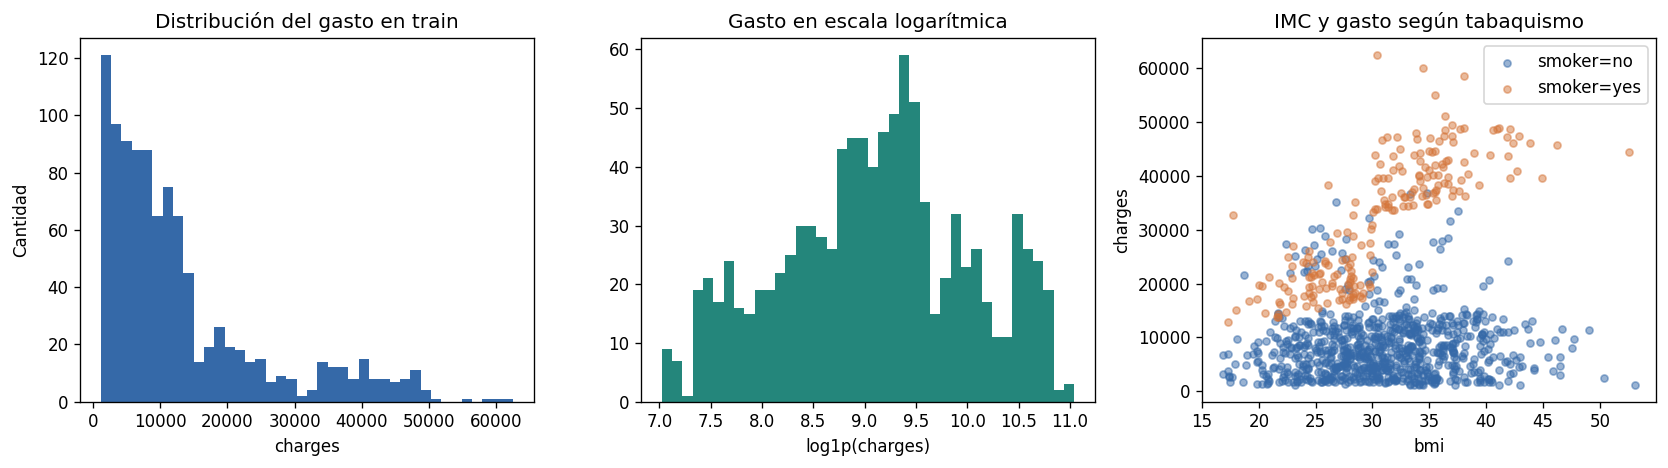

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(y_train, bins=40, color='#3569a8')
axes[0].set(title='Distribución del gasto en train', xlabel='charges', ylabel='Cantidad')
axes[1].hist(np.log1p(y_train), bins=40, color='#24867b')
axes[1].set(title='Gasto en escala logarítmica', xlabel='log1p(charges)')
for label, color in [('no', '#3569a8'), ('yes', '#d5763b')]:
    grupo = train_df[train_df['smoker'].eq(label)]
    axes[2].scatter(grupo['bmi'], grupo['charges'], alpha=.5, s=18,
                    color=color, label=f'smoker={label}')
axes[2].set(title='IMC y gasto según tabaquismo', xlabel='bmi', ylabel='charges')
axes[2].legend()
fig.tight_layout()
plt.show()

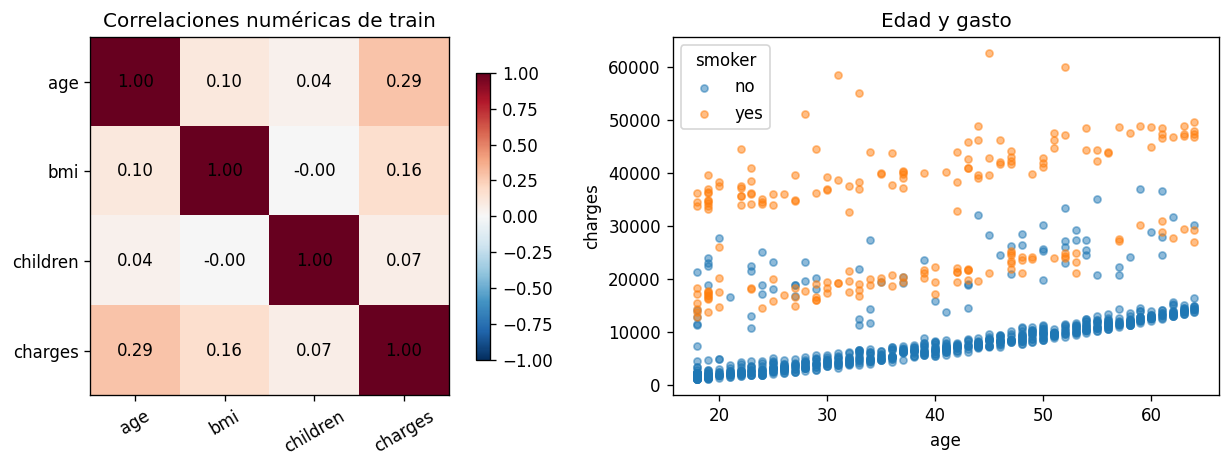

In [6]:
correlacion = train_df[['age', 'bmi', 'children', 'charges']].corr()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(correlacion, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xticks(range(4), correlacion.columns, rotation=30)
axes[0].set_yticks(range(4), correlacion.index)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f'{correlacion.iloc[i,j]:.2f}', ha='center', va='center')
axes[0].set_title('Correlaciones numéricas de train')
fig.colorbar(im, ax=axes[0], shrink=.8)
for label in ['no', 'yes']:
    grupo = train_df[train_df['smoker'].eq(label)]
    axes[1].scatter(grupo['age'], grupo['charges'], alpha=.5, s=18, label=label)
axes[1].set(title='Edad y gasto', xlabel='age', ylabel='charges')
axes[1].legend(title='smoker')
fig.tight_layout()
plt.show()

## 5. Interacciones y exclusión de columnas

Probamos la curvatura con la edad, cambios de pendiente según tabaquismo y un salto hipotético alrededor de IMC 30. Las columnas se calculan solo con entradas disponibles al predecir, sin usar `charges`.

Analizamos cada interacción por separado, todas juntas y el conjunto sin umbral. También probamos quitar sexo, región o ambas. Para aislar esos cambios, la tabla de ablation usa el mismo `alpha=10`. Después ajustamos alpha y configuración conjuntamente por CV.

La importancia baja de una variable no reemplaza estas comparaciones. El umbral de IMC es una hipótesis de modelado, no una conclusión clínica.

In [7]:
def seleccionar_columnas(X, columnas):
    return X.loc[:, columnas].copy()


def agregar_interacciones(X, extras):
    X = X.copy()
    fumador = X['smoker'].eq('yes').astype(int)
    valores = {
        'age_squared': X['age'] ** 2,
        'bmi_smoker': X['bmi'] * fumador,
        'age_smoker': X['age'] * fumador,
        'bmi_ge30_smoker': (X['bmi'] >= 30).astype(int) * fumador
    }
    for nombre in extras:
        X[nombre] = valores[nombre]
    return X


EXTRA = ('age_squared', 'bmi_smoker', 'age_smoker', 'bmi_ge30_smoker')
VARIANTES_RIDGE = {
    'Sin interacciones': {'extras': ()},
    'Solo edad²': {'extras': ('age_squared',)},
    'Solo IMC × fumador': {'extras': ('bmi_smoker',)},
    'Solo edad × fumador': {'extras': ('age_smoker',)},
    'Solo umbral IMC × fumador': {'extras': ('bmi_ge30_smoker',)},
    'Todas las interacciones': {'extras': EXTRA},
    'Interacciones sin umbral': {'extras': EXTRA[:-1]},
    'Todas, sin sexo': {'extras': EXTRA, 'quitar': ('sex',)},
    'Todas, sin región': {'extras': EXTRA, 'quitar': ('region',)},
    'Todas, sin sexo ni región': {'extras': EXTRA, 'quitar': ('sex', 'region')}
}
display(agregar_interacciones(X_train.head(6), EXTRA))

,age,sex,bmi,children,smoker,region,age_squared,bmi_smoker,age_smoker,bmi_ge30_smoker
1271,25,female,34.485,0,no,northwest,625,0.0,0,0
273,50,male,27.455,1,no,northeast,2500,0.0,0,0
723,19,male,35.400,0,no,southwest,361,0.0,0,0
1216,40,male,25.080,0,no,southeast,1600,0.0,0,0
1253,40,female,29.300,4,no,southwest,1600,0.0,0,0
100,41,female,31.600,0,no,southwest,1681,0.0,0,0


## 6. Preprocesamiento dentro del pipeline

El pipeline encadena preparación y modelo. En cada fold, el escalador y el encoder aprenden únicamente con la parte de entrenamiento del fold.

- Lineal, Ridge y SVR: estandarización de numéricas y one-hot para categorías.
- Random Forest y HistGradientBoosting: one-hot, sin escalado numérico.
- CatBoost: recibe categorías como texto y sus nombres en `cat_features`.

La imputación está preparada para los pipelines, aunque este CSV no tiene nulos. No ajustamos transformaciones sobre el test.

En el workshop el escalado se hacía antes del split. En regresión lineal ordinaria con intercepto, un cambio de escala lineal suele modificar poco las predicciones; aun así, el orden del procedimiento debe corregirse, especialmente para modelos regularizados o SVR.

In [8]:
def crear_preprocesador(columnas, escalar=True):
    categoricas = [c for c in columnas if c in CATEGORICAS]
    numericas = [c for c in columnas if c not in CATEGORICAS]
    pasos_numericos = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_numericos.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos_numericos), numericas),
        ('categoricas', Pipeline([
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('codificar', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
        ]), categoricas)
    ])


def crear_pipeline(estimador, columnas=FEATURES, escalar=True, extras=()):
    pasos = [('columnas', FunctionTransformer(seleccionar_columnas,
                                             kw_args={'columnas': columnas}))]
    if extras:
        pasos.append(('interacciones', FunctionTransformer(agregar_interacciones,
                                                           kw_args={'extras': extras})))
    pasos += [('preprocesar', crear_preprocesador(list(columnas) + list(extras), escalar)),
              ('modelo', estimador)]
    return Pipeline(pasos)

## 7. Cómo funciona CatBoost

CatBoost combina árboles mediante **gradient boosting**. Los árboles se agregan sucesivamente para reducir los errores que quedan. Con pérdida cuadrática, sus correcciones se relacionan con los residuos.

Ejemplo: gasto real 15000, predicción actual 10000 → falta +5000. El siguiente árbol aprende patrones de corrección a partir de muchos ejemplos. Con `learning_rate=0.05` se agrega una fracción de su salida en ese paso, no toda la corrección de golpe.

Para las categorías puede usar indicadores internos y estadísticas relacionadas con el target. Esas estadísticas se construyen con permutaciones y filas anteriores, evitando usar directamente el target de la propia fila; en regresión puede haber cuantización del target. No equivale a calcular medias por región sobre todo el dataset.

`Ordered` boosting es otra técnica para reducir sesgos de entrenamiento; aquí lo activamos explícitamente. Ninguna de estas técnicas corrige una fuga externa si nosotros usamos el test para elegir variables.

| Parámetro | Qué controla |
| --- | --- |
| iterations | Cantidad máxima de árboles |
| depth | Profundidad de los árboles |
| learning_rate | Tamaño de cada corrección |
| l2_leaf_reg | Regularización de las hojas |
| cat_features | Columnas categóricas |

Fuentes: [categorías](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic), [parámetros](https://catboost.ai/docs/en/concepts/parameter-tuning), [paper original](https://arxiv.org/abs/1706.09516).

## 8. Configuraciones que vamos a probar

Cada configuración es una hipótesis explícita; crear un modelo nuevo en cada fold evita reutilizar entrenamiento previo.

- Ridge: cinco valores de alpha para diez variantes de features (50 configuraciones).
- CatBoost: pérdida RMSE, pérdida MAE y target logarítmico, con profundidad 3/5 y regularización 3/10 (12 configuraciones). Mantenemos 300 árboles y tasa 0.05 para acotar el costo; las dos pérdidas tienen el mismo presupuesto.
- Referencias: Dummy media/mediana, Lineal, Random Forest, HistGradientBoosting y SVR.

No hay una búsqueda exhaustiva para todas las familias: comparamos las configuraciones incluidas. En CatBoost log volvemos a la escala original antes de calcular todas las métricas.

In [9]:
ALPHAS = [0.01, 0.1, 1, 10, 100]
CONFIGURACIONES = [
    {'id': 'Dummy media', 'familia': 'Dummy', 'modelo': 'dummy', 'strategy': 'mean'},
    {'id': 'Dummy mediana', 'familia': 'Dummy', 'modelo': 'dummy', 'strategy': 'median'},
    {'id': 'Lineal completa', 'familia': 'Lineal', 'modelo': 'lineal'},
    {'id': 'Random Forest', 'familia': 'Random Forest', 'modelo': 'forest'},
    {'id': 'HistGradientBoosting', 'familia': 'HistGradientBoosting', 'modelo': 'hist'},
    {'id': 'SVR', 'familia': 'SVR', 'modelo': 'svr'}
]
for variante, opciones in VARIANTES_RIDGE.items():
    for alpha in ALPHAS:
        CONFIGURACIONES.append({
            'id': f'Ridge | {variante} | alpha={alpha}',
            'familia': 'Ridge', 'modelo': 'ridge', 'variante': variante,
            'alpha': alpha, **opciones
        })
for enfoque in ['RMSE', 'MAE', 'log']:
    for parametros in ParameterGrid({'depth': [3, 5], 'l2_leaf_reg': [3, 10]}):
        CONFIGURACIONES.append({
            'id': f'CatBoost {enfoque} | depth={parametros["depth"]} | l2={parametros["l2_leaf_reg"]}',
            'familia': 'CatBoost', 'modelo': 'catboost', 'enfoque': enfoque,
            **parametros
        })
CONFIG_POR_ID = {config['id']: config for config in CONFIGURACIONES}
assert len(CONFIG_POR_ID) == len(CONFIGURACIONES)


def crear_modelo(config):
    columnas = [c for c in FEATURES if c not in config.get('quitar', ())]
    tipo = config['modelo']
    if tipo == 'catboost':
        estimador = CatBoostRegressor(
            iterations=300, depth=config['depth'], learning_rate=0.05,
            l2_leaf_reg=config['l2_leaf_reg'],
            loss_function='MAE' if config['enfoque'] == 'MAE' else 'RMSE',
            boosting_type='Ordered', random_seed=SEMILLA, thread_count=2,
            verbose=False, allow_writing_files=False,
            cat_features=[c for c in columnas if c in CATEGORICAS]
        )
        return Pipeline([
            ('columnas', FunctionTransformer(seleccionar_columnas, kw_args={'columnas': columnas})),
            ('modelo', estimador)
        ])
    if tipo == 'dummy':
        return crear_pipeline(DummyRegressor(strategy=config['strategy']), escalar=False)
    if tipo == 'lineal':
        return crear_pipeline(LinearRegression())
    if tipo == 'ridge':
        return crear_pipeline(Ridge(alpha=config['alpha']), columnas, extras=config['extras'])
    if tipo == 'forest':
        return crear_pipeline(RandomForestRegressor(n_estimators=250,
            min_samples_leaf=4, random_state=SEMILLA, n_jobs=1), escalar=False)
    if tipo == 'hist':
        return crear_pipeline(HistGradientBoostingRegressor(max_iter=250,
            learning_rate=0.05, max_leaf_nodes=15, l2_regularization=10,
            early_stopping=False, random_state=SEMILLA), escalar=False)
    if tipo == 'svr':
        return crear_pipeline(SVR(C=10000, epsilon=200, gamma='scale'))
    raise ValueError(tipo)


def ajustar_modelo(config, datos, target):
    modelo = crear_modelo(config)
    y_fit = np.log1p(target) if config.get('enfoque') == 'log' else target
    modelo.fit(datos, y_fit)
    return modelo


def predecir_original(modelo, datos, config):
    prediccion = modelo.predict(datos)
    return np.expm1(prediccion) if config.get('enfoque') == 'log' else prediccion


print('Configuraciones:', len(CONFIGURACIONES))
print('Ridge: 50 | CatBoost: 12 | Referencias: 6')

Configuraciones: 68
Ridge: 50 | CatBoost: 12 | Referencias: 6


## 9. CV de exploración: los mismos cinco folds para todas las configuraciones

Calculamos RMSE y MAE en la escala original. También guardamos predicciones out-of-fold: cada registro se predice con un modelo que no se entrenó con esa fila.

Esta CV sirve para elegir configuraciones; su mejor puntuación puede ser optimista después de buscar. Más adelante evaluamos el **proceso de selección** con CV anidada.

RMSE penaliza más errores grandes; MAE mide la distancia absoluta media. No elegimos la métrica que favorece a un modelo: estudiamos ambas como dos objetivos diferentes desde el inicio.

In [10]:
def metricas(real, prediccion):
    return {'RMSE': float(np.sqrt(mean_squared_error(real, prediccion))),
            'MAE': float(mean_absolute_error(real, prediccion)),
            'R2': float(r2_score(real, prediccion))}


def evaluar_configuracion(config, datos, target, folds):
    detalle = []
    predicciones = np.full(len(datos), np.nan)
    for fold, (ajuste, validacion) in enumerate(folds, start=1):
        modelo = ajustar_modelo(config, datos.iloc[ajuste], target.iloc[ajuste])
        pred_val = predecir_original(modelo, datos.iloc[validacion], config)
        pred_train = predecir_original(modelo, datos.iloc[ajuste], config)
        predicciones[validacion] = pred_val
        detalle.append({'fold': fold, **metricas(target.iloc[validacion], pred_val),
                        'RMSE_train': metricas(target.iloc[ajuste], pred_train)['RMSE']})
    assert np.isfinite(predicciones).all()
    tabla = pd.DataFrame(detalle)
    resumen = {'id': config['id'], 'familia': config['familia'],
               'RMSE_CV': tabla['RMSE'].mean(), 'DE_RMSE': tabla['RMSE'].std(ddof=1),
               'MAE_CV': tabla['MAE'].mean(), 'DE_MAE': tabla['MAE'].std(ddof=1),
               'R2_CV': tabla['R2'].mean(), 'RMSE_train': tabla['RMSE_train'].mean()}
    return resumen, tabla, predicciones


folds_cv = list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_train))
filas_cv, detalles_cv, predicciones_cv = [], {}, {}
for numero, config in enumerate(CONFIGURACIONES, start=1):
    if numero == 1 or numero % 10 == 0:
        print(f'CV: configuración {numero}/{len(CONFIGURACIONES)}')
    resumen, detalle, pred = evaluar_configuracion(config, X_train, y_train, folds_cv)
    filas_cv.append(resumen)
    detalles_cv[config['id']] = detalle
    predicciones_cv[config['id']] = pred
resultados_cv = pd.DataFrame(filas_cv).sort_values('RMSE_CV').reset_index(drop=True)
display(resultados_cv.head(12).round(3))

CV: configuración 1/68
CV: configuración 10/68
CV: configuración 20/68
CV: configuración 30/68
CV: configuración 40/68
CV: configuración 50/68
CV: configuración 60/68


,id,familia,RMSE_CV,DE_RMSE,MAE_CV,DE_MAE,R2_CV,RMSE_train
0,Ridge | Todas las interacciones | alpha=1,Ridge,4475.146,559.921,2398.592,211.418,0.860,4450.628
1,Ridge | Todas las interacciones | alpha=0.1,Ridge,4476.286,561.443,2400.024,213.024,0.860,4450.371
2,Ridge | Todas las interacciones | alpha=0.01,Ridge,4476.473,561.607,2400.267,213.222,0.860,4450.368
3,"Ridge | Todas, sin sexo | alpha=1",Ridge,4478.038,548.570,2397.799,206.576,0.860,4459.696
4,"Ridge | Todas, sin sexo | alpha=0.1",Ridge,4479.226,549.941,2398.881,208.548,0.860,4459.441
5,"Ridge | Todas, sin sexo | alpha=0.01",Ridge,4479.423,550.096,2399.101,208.790,0.860,4459.437
6,Ridge | Todas las interacciones | alpha=10,Ridge,4480.039,550.066,2402.195,201.824,0.860,4459.531
7,"Ridge | Todas, sin sexo | alpha=10",Ridge,4483.060,540.459,2403.788,196.512,0.860,4468.510
8,"Ridge | Todas, sin región | alpha=1",Ridge,4490.175,549.427,2408.710,197.341,0.859,4479.634
9,"Ridge | Todas, sin región | alpha=0.1",Ridge,4491.103,550.960,2409.998,198.945,0.859,4479.395


## 10. Qué interacciones y columnas aportan

Primero comparamos cada cambio manteniendo `alpha=10`: así no confundimos el aporte de features con un cambio de regularización. Después mostramos qué alpha da el menor RMSE de CV para cada variante.

Una diferencia pequeña no prueba que una variable sea inútil o que una configuración sea superior en una nueva población.

In [11]:
filas_ridge = resultados_cv[resultados_cv['familia'].eq('Ridge')].copy()
filas_ridge['variante'] = filas_ridge['id'].map(lambda clave: CONFIG_POR_ID[clave]['variante'])
filas_ridge['alpha'] = filas_ridge['id'].map(lambda clave: CONFIG_POR_ID[clave]['alpha'])
ablacion = filas_ridge[filas_ridge['alpha'].eq(10)].copy()
base_rmse = ablacion.loc[ablacion['variante'].eq('Todas las interacciones'), 'RMSE_CV'].iloc[0]
ablacion['cambio_RMSE_vs_todas'] = ablacion['RMSE_CV'] - base_rmse
print('Ablation: alpha fijo en 10; cambios positivos implican empeorar respecto de todas las interacciones.')
display(ablacion[['variante', 'RMSE_CV', 'MAE_CV', 'cambio_RMSE_vs_todas']].round(2))

mejor_ridge_variante = filas_ridge.sort_values('RMSE_CV').drop_duplicates('variante')
print('Mejor alpha por variante, según RMSE de CV:')
display(mejor_ridge_variante[['variante', 'alpha', 'RMSE_CV', 'MAE_CV']].round(2))

Ablation: alpha fijo en 10; cambios positivos implican empeorar respecto de todas las interacciones.
Mejor alpha por variante, según RMSE de CV:


,variante,RMSE_CV,MAE_CV,cambio_RMSE_vs_todas
6,Todas las interacciones,4480.04,2402.20,0.00
7,"Todas, sin sexo",4483.06,2403.79,3.02
14,"Todas, sin región",4495.05,2409.76,15.01
15,"Todas, sin sexo ni región",4497.05,2410.91,17.01
22,Solo umbral IMC × fumador,4599.42,2673.66,119.38
45,Interacciones sin umbral,5135.85,3165.82,655.81
46,Solo IMC × fumador,5188.71,3211.10,708.67
60,Solo edad²,6237.10,4348.76,1757.07
61,Sin interacciones,6271.50,4388.94,1791.46
62,Solo edad × fumador,6331.77,4326.23,1851.73


,variante,alpha,RMSE_CV,MAE_CV
0,Todas las interacciones,1.00,4475.15,2398.59
3,"Todas, sin sexo",1.00,4478.04,2397.80
8,"Todas, sin región",1.00,4490.18,2408.71
11,"Todas, sin sexo ni región",1.00,4491.81,2408.22
16,Solo umbral IMC × fumador,0.01,4573.28,2554.77
38,Interacciones sin umbral,0.10,4951.22,2984.77
41,Solo IMC × fumador,0.10,4990.78,3012.17
50,Solo edad²,0.10,6195.40,4202.35
53,Solo edad × fumador,0.01,6228.54,4237.95
56,Sin interacciones,0.10,6233.35,4248.00


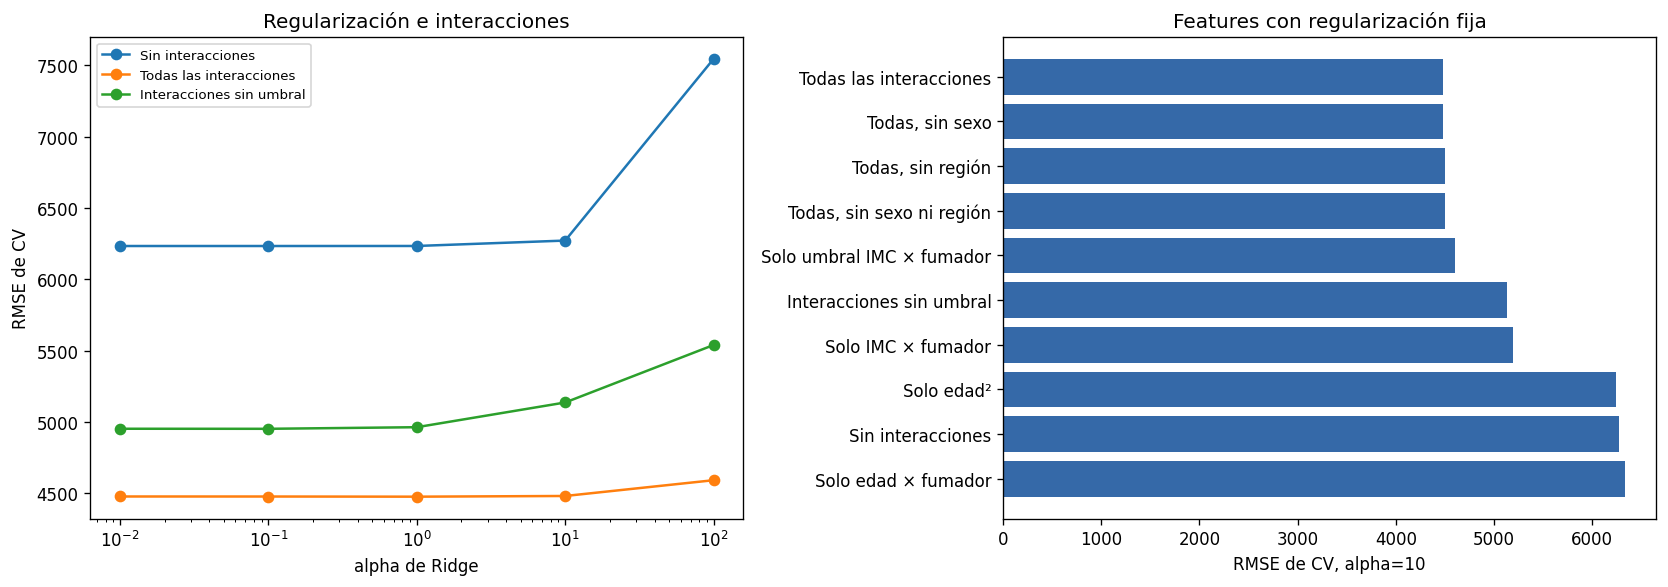

In [12]:
CARPETA_FIGURAS = Path('figuras')
CARPETA_FIGURAS.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for variante in ['Sin interacciones', 'Todas las interacciones', 'Interacciones sin umbral']:
    parte = filas_ridge[filas_ridge['variante'].eq(variante)].sort_values('alpha')
    axes[0].plot(parte['alpha'], parte['RMSE_CV'], marker='o', label=variante)
axes[0].set(xscale='log', xlabel='alpha de Ridge', ylabel='RMSE de CV', title='Regularización e interacciones')
axes[0].legend(fontsize=8)
orden = ablacion.sort_values('RMSE_CV', ascending=False)
axes[1].barh(orden['variante'], orden['RMSE_CV'], color='#3569a8')
axes[1].set(xlabel='RMSE de CV, alpha=10', title='Features con regularización fija')
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / 'interacciones_ridge.png', dpi=160, bbox_inches='tight')
plt.show()

## 11. CatBoost: pérdida RMSE, pérdida MAE y target logarítmico

Las tres opciones tienen cuatro configuraciones cada una. Comparamos tanto el mejor RMSE como el mejor MAE de cada enfoque, sin confundir pérdida de entrenamiento con métrica de evaluación.

La pérdida cuadrática apunta a la media condicional; la pérdida absoluta, a la mediana. El logaritmo cambia qué errores se priorizan y no estima automáticamente la media en la escala original. Una opción puede mejorar MAE y empeorar RMSE.

,seleccion_por,enfoque,id,RMSE_CV,MAE_CV
0,RMSE,RMSE,CatBoost RMSE | depth=3 | l2=10,4642.32,2573.12
1,RMSE,log,CatBoost log | depth=5 | l2=3,4719.66,2168.05
2,RMSE,MAE,CatBoost MAE | depth=5 | l2=3,4734.25,1689.56
3,MAE,MAE,CatBoost MAE | depth=5 | l2=3,4734.25,1689.56
4,MAE,log,CatBoost log | depth=5 | l2=3,4719.66,2168.05
5,MAE,RMSE,CatBoost RMSE | depth=3 | l2=3,4663.61,2565.37


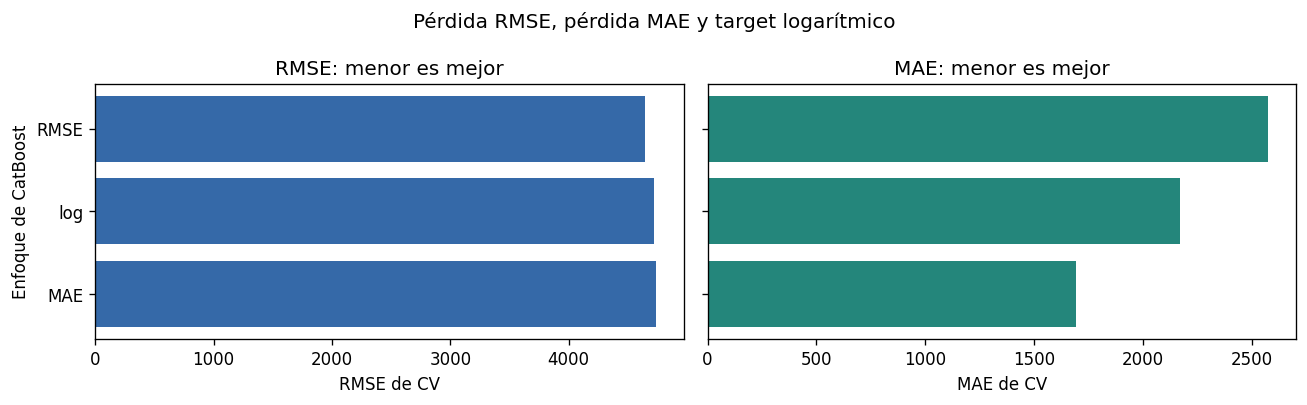

In [13]:
filas_catboost = resultados_cv[resultados_cv['familia'].eq('CatBoost')].copy()
filas_catboost['enfoque'] = filas_catboost['id'].map(lambda clave: CONFIG_POR_ID[clave]['enfoque'])
comparacion_perdidas = []
for criterio in ['RMSE', 'MAE']:
    mejores = filas_catboost.sort_values(f'{criterio}_CV').drop_duplicates('enfoque').copy()
    mejores['seleccion_por'] = criterio
    comparacion_perdidas.append(mejores)
comparacion_perdidas = pd.concat(comparacion_perdidas, ignore_index=True)
display(comparacion_perdidas[['seleccion_por', 'enfoque', 'id', 'RMSE_CV', 'MAE_CV']].round(2))

# Mismas configuraciones en los dos paneles; una por enfoque, elegida por RMSE.
perdidas_para_grafico = comparacion_perdidas[
    comparacion_perdidas['seleccion_por'].eq('RMSE')].sort_values('RMSE_CV', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, columna, color in [(axes[0], 'RMSE_CV', '#3569a8'),
                            (axes[1], 'MAE_CV', '#24867b')]:
    ax.barh(perdidas_para_grafico['enfoque'], perdidas_para_grafico[columna], color=color)
    ax.set(xlabel=columna.replace('_CV', '') + ' de CV',
           title=columna.replace('_CV', '') + ': menor es mejor')
axes[0].set_ylabel('Enfoque de CatBoost')
fig.suptitle('Pérdida RMSE, pérdida MAE y target logarítmico', fontsize=12)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / 'perdidas_catboost.png', dpi=160, bbox_inches='tight')
plt.show()


## 12. Gráfico principal: una configuración por familia

Para evitar mezclar todas las variantes en una sola figura, tomamos la configuración de menor RMSE por familia. **Los dos paneles muestran exactamente esas mismas configuraciones**; no cambiamos el candidato entre paneles.

La tabla siguiente también muestra los candidatos elegidos por RMSE y por MAE considerando todas las configuraciones. Las barras de error son desviaciones entre folds, no intervalos de confianza.

Candidato elegido por RMSE: Ridge | Todas las interacciones | alpha=1
Candidato elegido por MAE: CatBoost MAE | depth=5 | l2=3


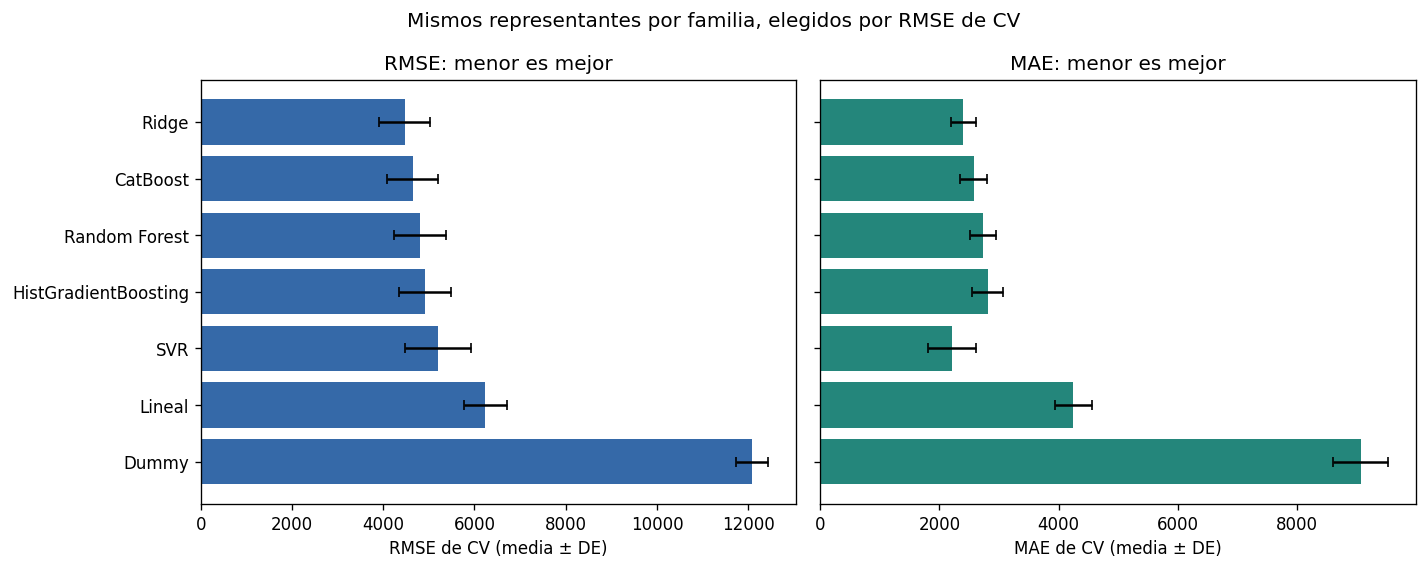

,familia,id,RMSE_CV,MAE_CV
0,Ridge,Ridge | Todas las interacciones | alpha=1,4475.15,2398.59
24,CatBoost,CatBoost RMSE | depth=3 | l2=10,4642.32,2573.12
36,Random Forest,Random Forest,4804.06,2732.45
37,HistGradientBoosting,HistGradientBoosting,4914.60,2808.66
47,SVR,SVR,5197.65,2216.43
58,Lineal,Lineal completa,6233.36,4246.65
66,Dummy,Dummy media,12089.54,9067.25


In [14]:
representantes = resultados_cv.sort_values('RMSE_CV').drop_duplicates('familia').copy()
representantes = representantes.sort_values('RMSE_CV', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, metrica, desviacion, color in [
    (axes[0], 'RMSE_CV', 'DE_RMSE', '#3569a8'),
    (axes[1], 'MAE_CV', 'DE_MAE', '#24867b')
]:
    ax.barh(representantes['familia'], representantes[metrica],
            xerr=representantes[desviacion], color=color, capsize=3)
    ax.set(xlabel=f'{metrica.replace("_CV", "")} de CV (media ± DE)',
           title=metrica.replace('_CV', '') + ': menor es mejor')
fig.suptitle('Mismos representantes por familia, elegidos por RMSE de CV', fontsize=12)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / 'comparacion_rmse_mae.png', dpi=160, bbox_inches='tight')
plt.show()
display(representantes[['familia', 'id', 'RMSE_CV', 'MAE_CV']].sort_values('RMSE_CV').round(2))

CONFIG_FINAL = {}
for criterio in ['RMSE', 'MAE']:
    clave = resultados_cv.sort_values(f'{criterio}_CV').iloc[0]['id']
    CONFIG_FINAL[criterio] = CONFIG_POR_ID[clave]
    print(f'Candidato elegido por {criterio}: {clave}')

## 13. CV anidada: evaluar el proceso de selección

La CV anterior utiliza los mismos folds para elegir y mostrar el mejor puntaje. En CV anidada, cada fold externo se mantiene fuera de la búsqueda:

1. Dividimos train en tres folds externos.
2. En los otros dos folds hacemos una búsqueda con tres folds internos, entre las mismas configuraciones predefinidas.
3. Elegimos un candidato por RMSE y otro por MAE internos.
4. Predecimos el fold externo con cada candidato elegido, sin usarlo para ajustar.

Las predicciones externas permiten revisar errores sin reutilizar test. Evalúan dos **procedimientos de selección**, no necesariamente un mismo modelo fijo en cada fold.

Se usan 3×3 folds para mantener un tiempo razonable. La variación entre folds no es una prueba de significancia. Es una estimación interna del procedimiento, no una nueva validación externa: los datos y varias hipótesis ya se exploraron en este proyecto. Esta celda puede tardar algunos minutos en CPU.

In [15]:
folds_externos = list(KFold(n_splits=3, shuffle=True, random_state=2026).split(X_train))
pred_anidadas = {criterio: np.full(len(X_train), np.nan) for criterio in ['RMSE', 'MAE']}
filas_anidadas, modelos_externos = [], []

for fold, (ajuste, externo) in enumerate(folds_externos, start=1):
    print(f'CV anidada: fold externo {fold}/3', flush=True)
    X_ajuste, y_ajuste = X_train.iloc[ajuste], y_train.iloc[ajuste]
    folds_internos = list(KFold(n_splits=3, shuffle=True,
                              random_state=SEMILLA + fold).split(X_ajuste))
    busqueda_interna = []
    for config in CONFIGURACIONES:
        resumen, _, _ = evaluar_configuracion(config, X_ajuste, y_ajuste, folds_internos)
        busqueda_interna.append(resumen)
    busqueda_interna = pd.DataFrame(busqueda_interna)

    for criterio in ['RMSE', 'MAE']:
        clave = busqueda_interna.sort_values(f'{criterio}_CV').iloc[0]['id']
        config = CONFIG_POR_ID[clave]
        modelo = ajustar_modelo(config, X_ajuste, y_ajuste)
        pred = predecir_original(modelo, X_train.iloc[externo], config)
        pred_anidadas[criterio][externo] = pred
        filas_anidadas.append({'criterio': criterio, 'fold_externo': fold,
                               'seleccionado': clave,
                               **metricas(y_train.iloc[externo], pred)})
        modelos_externos.append({'criterio': criterio, 'fold': fold,
                                'validacion': externo, 'ajuste': ajuste,
                                'config': config, 'modelo': modelo})

for pred in pred_anidadas.values():
    assert np.isfinite(pred).all()
resultado_anidado_folds = pd.DataFrame(filas_anidadas)
resumen_anidado = pd.DataFrame([
    {'seleccion_por': criterio, **metricas(y_train, pred_anidadas[criterio])}
    for criterio in ['RMSE', 'MAE']
])
print('Métricas sobre todas las predicciones externas reunidas (OOF):')
display(resumen_anidado.round(3))
print('Configuraciones elegidas dentro de cada fold, sin consultar su validación externa:')
display(resultado_anidado_folds.round(3))

CV anidada: fold externo 1/3
CV anidada: fold externo 2/3
CV anidada: fold externo 3/3
Métricas sobre todas las predicciones externas reunidas (OOF):
Configuraciones elegidas dentro de cada fold, sin consultar su validación externa:


,seleccion_por,RMSE,MAE,R2
0,RMSE,4526.829,2401.339,0.860
1,MAE,4849.172,1802.077,0.839


,criterio,fold_externo,seleccionado,RMSE,MAE,R2
0,RMSE,1,"Ridge | Todas, sin región | alpha=10",4400.555,2444.489,0.851
1,MAE,1,CatBoost MAE | depth=3 | l2=10,4600.899,1680.391,0.837
2,RMSE,2,Ridge | Todas las interacciones | alpha=0.1,4584.557,2393.195,0.862
3,MAE,2,CatBoost MAE | depth=3 | l2=3,5021.113,1930.277,0.834
4,RMSE,3,Ridge | Todas las interacciones | alpha=1,4592.765,2366.333,0.864
5,MAE,3,CatBoost MAE | depth=5 | l2=3,4915.645,1795.563,0.844


## 14. Diagnóstico de residuos con predicciones externas

Ahora revisamos el equilibrio entre sobreestimar muchos casos y subestimar pocos casos por grandes montos. Los gráficos usan las predicciones externas de CV anidada dentro de train.

No eliminamos gastos altos, no desplazamos las predicciones usando el residuo mediano y no elegimos los casos que hacen quedar mejor a un modelo. Este diagnóstico puede sugerir futuras hipótesis, que requerirán una nueva evaluación del procedimiento.

,seleccion_por,n,sobreestimados_%,residuo_mediano,residuo_medio,subestimados_mas_de_10000,percentil_95_error_absoluto
0,RMSE,1002,88.92,-1263.54,18.17,65,13164.10
1,MAE,1002,49.10,6.65,1341.12,74,14493.71


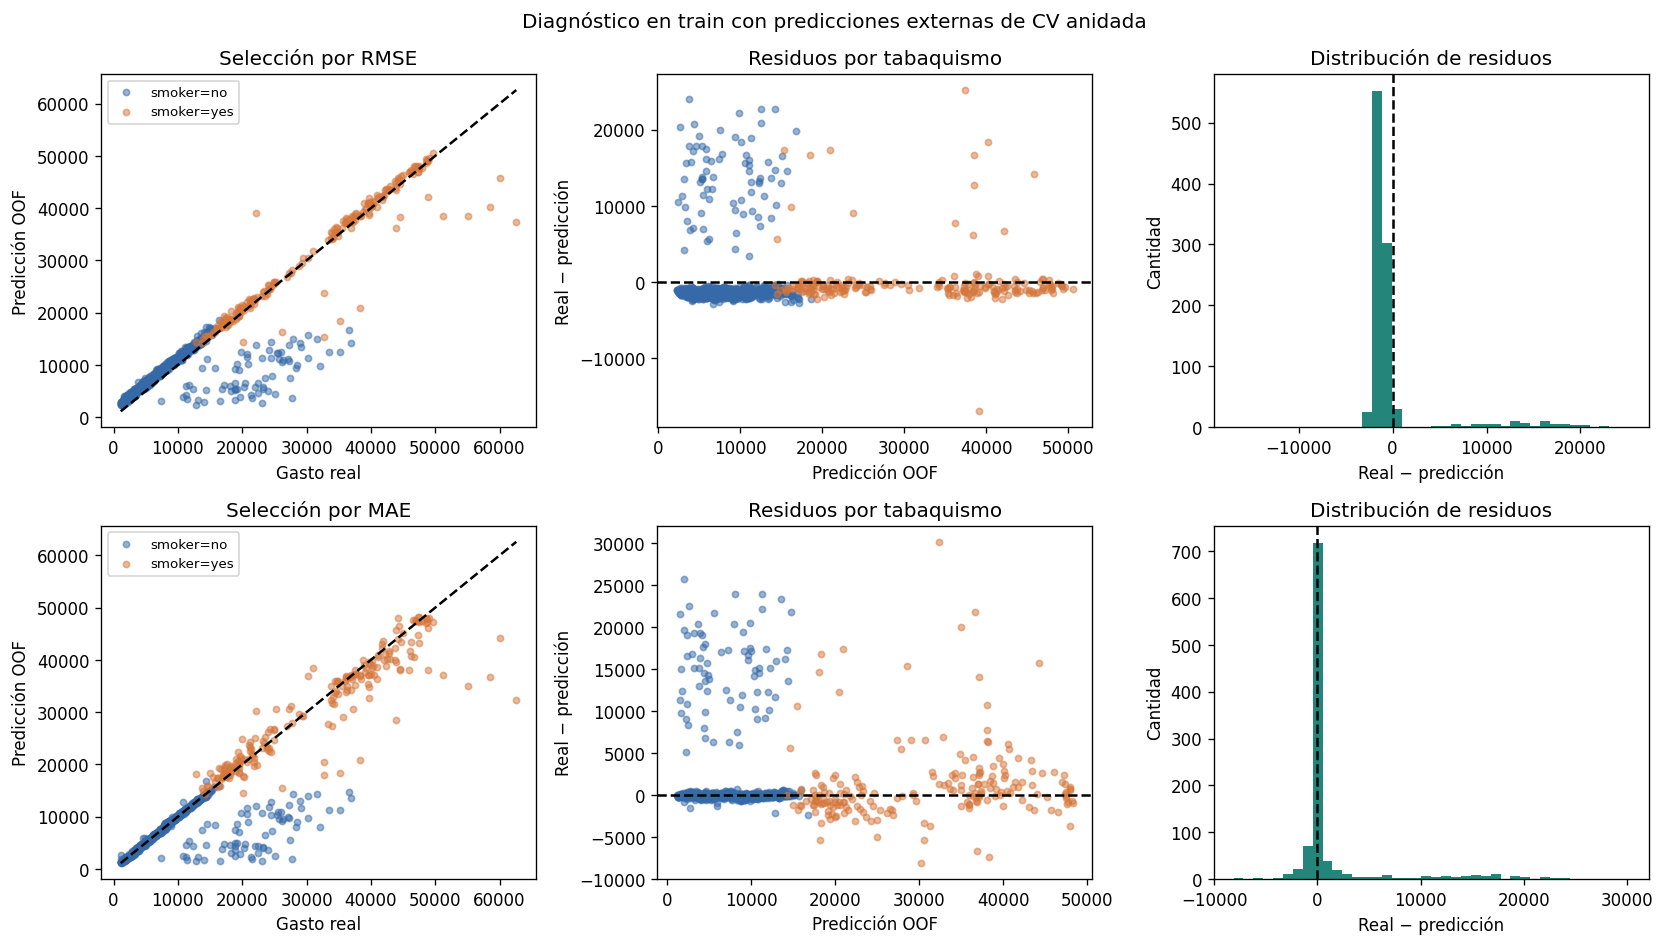

In [16]:
diagnostico_residuos = []
for criterio, pred in pred_anidadas.items():
    residuo = y_train.to_numpy() - pred
    diagnostico_residuos.append({
        'seleccion_por': criterio, 'n': len(residuo),
        'sobreestimados_%': 100 * (residuo < 0).mean(),
        'residuo_mediano': np.median(residuo),
        'residuo_medio': residuo.mean(),
        'subestimados_mas_de_10000': int((residuo > 10000).sum()),
        'percentil_95_error_absoluto': np.quantile(np.abs(residuo), .95)
    })
diagnostico_residuos = pd.DataFrame(diagnostico_residuos)
display(diagnostico_residuos.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for fila, criterio in enumerate(['RMSE', 'MAE']):
    pred = pred_anidadas[criterio]
    residuo = y_train.to_numpy() - pred
    for label, color in [('no', '#3569a8'), ('yes', '#d5763b')]:
        mascara = X_train['smoker'].eq(label).to_numpy()
        axes[fila, 0].scatter(y_train.to_numpy()[mascara], pred[mascara],
                              alpha=.5, s=14, color=color, label=f'smoker={label}')
        axes[fila, 1].scatter(pred[mascara], residuo[mascara],
                              alpha=.5, s=14, color=color)
    limites = [min(y_train.min(), pred.min()), max(y_train.max(), pred.max())]
    axes[fila, 0].plot(limites, limites, '--', color='black')
    axes[fila, 0].set(xlabel='Gasto real', ylabel='Predicción OOF', title=f'Selección por {criterio}')
    axes[fila, 0].legend(fontsize=8)
    axes[fila, 1].axhline(0, linestyle='--', color='black')
    axes[fila, 1].set(xlabel='Predicción OOF', ylabel='Real − predicción', title='Residuos por tabaquismo')
    axes[fila, 2].hist(residuo, bins=40, color='#24867b')
    axes[fila, 2].axvline(0, linestyle='--', color='black')
    axes[fila, 2].set(xlabel='Real − predicción', ylabel='Cantidad', title='Distribución de residuos')
fig.suptitle('Diagnóstico en train con predicciones externas de CV anidada', fontsize=12)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / 'residuos_oof.png', dpi=160, bbox_inches='tight')
plt.show()

## 15. Error por grupos y casos difíciles

Comparamos MAE y RMSE junto con el tamaño de cada grupo. R² depende de la variabilidad del gasto dentro del grupo: no es un porcentaje de aciertos y no basta para comparar grupos diferentes.

Los errores grandes pueden corresponder a información ausente en estas seis columnas. Eso es una hipótesis, no una causa demostrada. No hay que borrar registros solo porque el modelo falla.

In [17]:
tablas_oof, filas_grupos = {}, []
for criterio, pred in pred_anidadas.items():
    tabla_oof = X_train.copy()
    tabla_oof['real'] = y_train
    tabla_oof['predicho'] = pred
    tabla_oof['residuo'] = y_train.to_numpy() - pred
    tabla_oof['error_absoluto'] = np.abs(tabla_oof['residuo'])
    tablas_oof[criterio] = tabla_oof
    for columna in ['smoker', 'sex', 'region']:
        for valor, grupo in tabla_oof.groupby(columna):
            filas_grupos.append({'seleccion_por': criterio, 'variable': columna,
                                 'grupo': valor, 'n': len(grupo),
                                 **metricas(grupo['real'], grupo['predicho'])})
metricas_grupos = pd.DataFrame(filas_grupos)
display(metricas_grupos.round(3))
for criterio in ['RMSE', 'MAE']:
    print(f'Mayores errores OOF: selección por {criterio}')
    display(tablas_oof[criterio].nlargest(5, 'error_absoluto').round(2))

Mayores errores OOF: selección por RMSE
Mayores errores OOF: selección por MAE


,seleccion_por,variable,grupo,n,RMSE,MAE,R2
0,RMSE,smoker,no,797,4650.108,2576.246,0.410
1,RMSE,smoker,yes,205,4011.710,1721.332,0.881
2,RMSE,sex,female,486,4524.669,2438.888,0.833
3,RMSE,sex,male,516,4528.862,2365.972,0.878
4,RMSE,region,northeast,248,4899.039,2800.011,0.809
5,RMSE,region,northwest,236,4780.096,2458.295,0.800
6,RMSE,region,southeast,276,4443.894,2383.314,0.898
7,RMSE,region,southwest,242,3930.218,1957.795,0.889
8,MAE,smoker,no,797,4837.065,1567.499,0.361
9,MAE,smoker,yes,205,4895.957,2714.070,0.823


,age,sex,bmi,children,smoker,region,real,predicho,residuo,error_absoluto
1300,45,male,30.36,0,yes,southeast,62592.87,37420.27,25172.60,25172.60
516,20,male,35.31,1,no,southeast,27724.29,3698.85,24025.44,24025.44
1206,59,female,34.80,2,no,southwest,36910.61,14212.86,22697.75,22697.75
242,55,female,26.80,1,no,southwest,35160.13,12502.04,22658.09,22658.09
936,44,male,29.74,2,no,northeast,32108.66,9893.98,22214.68,22214.68


,age,sex,bmi,children,smoker,region,real,predicho,residuo,error_absoluto
1300,45,male,30.36,0,yes,southeast,62592.87,32398.09,30194.78,30194.78
516,20,male,35.31,1,no,southeast,27724.29,1944.72,25779.57,25779.57
936,44,male,29.74,2,no,northeast,32108.66,8118.90,23989.76,23989.76
242,55,female,26.80,1,no,southwest,35160.13,11242.73,23917.40,23917.40
1206,59,female,34.80,2,no,southwest,36910.61,13548.44,23362.16,23362.16


## 16. Importancia por permutación dentro de train

Usamos los modelos externos elegidos por RMSE y permutamos solo las filas de su validación externa. La importancia mide aumento de RMSE; no se usa para elegir nuevas columnas ni modifica las búsquedas anteriores.

Promediamos las importancias de los tres folds. La desviación muestra variación entre folds, no un intervalo de confianza. La permutación puede subestimar información compartida y crear combinaciones poco frecuentes; no prueba causalidad.

,feature,aumento_RMSE,DE_entre_folds
4,smoker,10929.12,454.04
2,bmi,3361.11,237.28
0,age,2423.28,74.25
3,children,142.18,24.84
5,region,23.86,33.91
1,sex,14.02,3.55


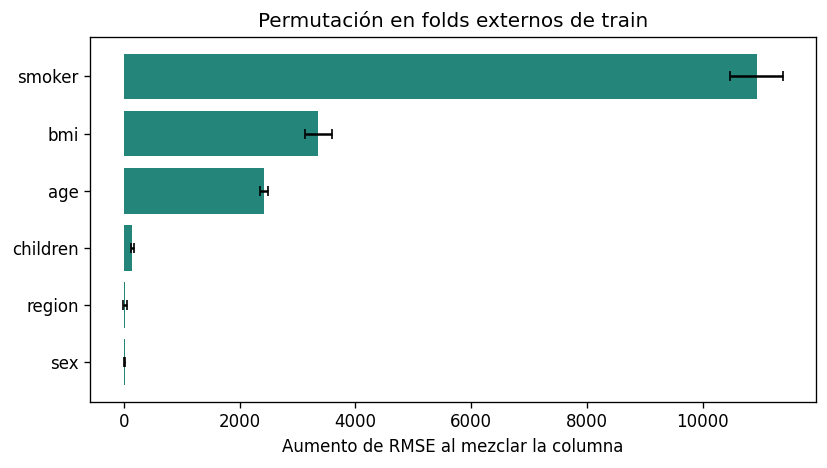

In [18]:
importancias_folds = []
for item in modelos_externos:
    if item['criterio'] != 'RMSE':
        continue
    config = item['config']
    def scoring_original(estimador, datos, target, config=config):
        return -metricas(target, predecir_original(estimador, datos, config))['RMSE']
    indices = item['validacion']
    importancia = permutation_importance(item['modelo'], X_train.iloc[indices],
        y_train.iloc[indices], scoring=scoring_original, n_repeats=10,
        random_state=SEMILLA + item['fold'], n_jobs=1)
    importancias_folds.append(importancia.importances_mean)
valores = np.asarray(importancias_folds)
importancias = pd.DataFrame({'feature': FEATURES,
    'aumento_RMSE': valores.mean(axis=0), 'DE_entre_folds': valores.std(axis=0, ddof=1)
}).sort_values('aumento_RMSE', ascending=False)
display(importancias.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
orden = importancias.iloc[::-1]
ax.barh(orden['feature'], orden['aumento_RMSE'], xerr=orden['DE_entre_folds'],
        color='#24867b', capsize=3)
ax.set(xlabel='Aumento de RMSE al mezclar la columna', title='Permutación en folds externos de train')
fig.tight_layout()
plt.show()

## 17. Resultado anterior de test: referencia histórica

Estos valores pertenecen a la primera versión, antes de incorporar las nuevas pruebas. Se conservan con su etiqueta histórica. **No son métricas de los candidatos ajustados en esta ampliación.**

No volvemos a predecir test ni recalculamos sus errores. Los nuevos resultados se informan como validación interna.

In [19]:
resultado_test_anterior = {
    'modelo': 'Ridge con todas las interacciones, alpha=10',
    'RMSE': 4090.2214509092937, 'MAE': 2277.1866788424095,
    'R2': 0.88695341105375, 'n_test': 335,
    'origen': 'Primera versión, ejecución previa a esta ampliación'
}
display(pd.Series(resultado_test_anterior, name='Referencia histórica'))

modelo          Ridge con todas las interacciones, alpha=10
RMSE                                            4090.221451
MAE                                             2277.186679
R2                                                 0.886953
n_test                                                  335
origen    Primera versión, ejecución previa a esta ampli...
Name: Referencia histórica, dtype: object

## 18. Ajustar los candidatos finales y hacer una predicción

Elegimos las configuraciones con toda la CV de train y entrenamos cada candidato sobre todo train. Es normal que la búsqueda interna de cada fold anidado elija otras configuraciones: su entrenamiento tiene menos filas.

Estos candidatos no reciben una métrica nueva de test. La CV anidada evalúa el procedimiento de selección, no el ajuste final particular sobre todas las filas de train. La salida del ejemplo está en unidades del dataset, no en pesos argentinos ni como una cotización.

In [20]:
modelos_finales = {criterio: ajustar_modelo(config, X_train, y_train)
                   for criterio, config in CONFIG_FINAL.items()}
ejemplo = pd.DataFrame([{'age': 35, 'sex': 'female', 'bmi': 27.0,
                        'children': 1, 'smoker': 'no', 'region': 'southwest'}])
display(ejemplo)
for criterio in ['RMSE', 'MAE']:
    valor = predecir_original(modelos_finales[criterio], ejemplo, CONFIG_FINAL[criterio])[0]
    print(f'Candidato seleccionado por {criterio}: {valor:,.2f}')

Candidato seleccionado por RMSE: 6,227.62
Candidato seleccionado por MAE: 5,200.18


,age,sex,bmi,children,smoker,region
0,35,female,27.0,1,no,southwest


## 19. Conclusiones calculadas a partir de esta corrida

Distinguimos el candidato elegido por cada criterio, la CV usada para buscar y la CV anidada usada para evaluar el procedimiento. No afirmamos que un algoritmo sea universalmente superior.

In [21]:
from IPython.display import Markdown

lineas_conclusion = []
for criterio in ['RMSE', 'MAE']:
    fila = resumen_anidado[resumen_anidado['seleccion_por'].eq(criterio)].iloc[0]
    lineas_conclusion += [
        f'**Selección por {criterio}:** {CONFIG_FINAL[criterio]["id"]}.',
        f'El procedimiento obtuvo RMSE **{fila["RMSE"]:,.2f}** y MAE **{fila["MAE"]:,.2f}** '
        'sobre predicciones externas reunidas de CV anidada.', ''
    ]
lineas_conclusion += [
    'Los dos objetivos pueden elegir configuraciones diferentes. '
    'Las métricas pertenecen a validación interna en train, no a un nuevo test.', '',
    'El diagnóstico de residuos muestra el equilibrio entre sobreestimaciones frecuentes '
    'y subestimaciones grandes. No se corrigieron predicciones ni se borraron casos usando ese diagnóstico.', '',
    'Para una conclusión externa se necesitan nuevos datos. No se elige una semilla por su resultado.'
]
display(Markdown('\n\n'.join(lineas_conclusion)))

**Selección por RMSE:** Ridge | Todas las interacciones | alpha=1.

El procedimiento obtuvo RMSE **4,526.83** y MAE **2,401.34** sobre predicciones externas reunidas de CV anidada.



**Selección por MAE:** CatBoost MAE | depth=5 | l2=3.

El procedimiento obtuvo RMSE **4,849.17** y MAE **1,802.08** sobre predicciones externas reunidas de CV anidada.



Los dos objetivos pueden elegir configuraciones diferentes. Las métricas pertenecen a validación interna en train, no a un nuevo test.



El diagnóstico de residuos muestra el equilibrio entre sobreestimaciones frecuentes y subestimaciones grandes. No se corrigieron predicciones ni se borraron casos usando ese diagnóstico.



Para una conclusión externa se necesitan nuevos datos. No se elige una semilla por su resultado.

## 20. README y gráficos para GitHub

Se genera un README breve con los dos objetivos, los resultados de CV anidada y cuatro figuras: comparación RMSE/MAE, pérdidas de CatBoost, interacciones de Ridge y residuos OOF por tabaquismo.

Para GitHub subimos este notebook, el README y `figuras/`. Todo el entrenamiento sigue dentro del notebook y el CSV se obtiene por URL. Al ejecutar, se actualizan las figuras y el README con esta corrida.

In [22]:
lineas = [
    '# Predicción de gastos médicos', '',
    'Proyecto educativo del workshop 2 de ciencia de datos. '
    'Un único notebook contiene la lectura por URL, exploración, modelos, ajuste y resultados.', '',
    '[Ver el notebook ejecutado](insurance_costs_regression_mejorado.ipynb)', '',
    '## Qué se estudia', '',
    '- Recuperar edad como predictor y ajustar transformaciones dentro de pipelines.',
    '- Ajustar alpha de Ridge y comparar interacciones y exclusión de columnas.',
    '- Comparar CatBoost con pérdida RMSE, pérdida MAE y target logarítmico.',
    '- Distinguir selección por RMSE y por MAE.',
    '- Evaluar el proceso de selección con CV anidada y analizar errores OOF.', '',
    '## Evaluación', '',
    f'Train: {len(X_train)} filas. Se conserva el split original y el test ya observado '
    'queda fuera de los nuevos experimentos. La búsqueda usa cinco folds de train; '
    'la CV anidada usa tres folds externos y tres internos, con la misma lista predefinida de candidatos.', '',
    'Las siguientes métricas se calculan reuniendo las predicciones externas (OOF) de la CV anidada. '
    'Evalúan dos procedimientos de selección; la configuración elegida puede cambiar entre folds.', '',
    '| Selección interna por | RMSE OOF anidado | MAE OOF anidado | R² OOF anidado |',
    '| --- | ---: | ---: | ---: |'
]
for fila in resumen_anidado.itertuples():
    lineas.append(f'| {fila.seleccion_por} | {fila.RMSE:,.2f} | {fila.MAE:,.2f} | {fila.R2:.4f} |')
lineas += ['', '### Candidatos para ajustar con todo train', '']
for criterio in ['RMSE', 'MAE']:
    lineas.append(f'- **{criterio}:** {CONFIG_FINAL[criterio]["id"]}.')
lineas += [
    '', '## Modelos e interacciones', '',
    'El gráfico principal muestra una configuración por familia, elegida por RMSE de CV. '
    'Ambos paneles muestran esas mismas configuraciones. Las barras de error son desviaciones entre folds, '
    'no intervalos de confianza. Los puntajes de búsqueda pueden ser optimistas por selección.', '',
    '![Comparación RMSE y MAE](figuras/comparacion_rmse_mae.png)', '',
    'CatBoost se muestra también por enfoque: pérdida cuadrática, pérdida absoluta y target logarítmico. '
    'Se conservan las mismas configuraciones entre paneles para visualizar el intercambio entre métricas.', '',
    '![Pérdidas de CatBoost](figuras/perdidas_catboost.png)', '',
    'La ablation compara features con alpha=10; la curva muestra el ajuste de alpha.', '',
    '![Interacciones y regularización de Ridge](figuras/interacciones_ridge.png)', '',
    '## Análisis de errores', '',
    'Predicciones de validación externa dentro de train; color por tabaquismo. '
    'Se estudia el equilibrio entre sobreestimaciones frecuentes y subestimaciones grandes. '
    'No se eliminan casos difíciles ni se corrigen predicciones a partir de estos gráficos.', '',
    '![Residuos de validación anidada](figuras/residuos_oof.png)', '',
    '## Referencia histórica de test', '',
    'La primera versión de Ridge con todas las interacciones y alpha=10 obtuvo '
    'RMSE 4090.22, MAE 2277.19 y R² 0.8870 en 335 filas de test. '
    '**Esos valores no corresponden a los nuevos candidatos.** '
    'El test se observó antes de esta ampliación y no se vuelve a evaluar.', '',
    '## Cómo reproducirlo', '',
    'Abrir el `.ipynb` en Jupyter o Google Colab y ejecutar las celdas en orden. '
    'La primera instala las bibliotecas. Los datos se leen desde la URL del workshop; '
    'no se necesitan scripts, un archivo de dependencias ni un CSV local. '
    'La CV anidada puede tardar algunos minutos en CPU. Las salidas ya están guardadas.', '',
    '## Datos y alcance', '',
    '[Medical Cost Personal Datasets — Miri Choi, Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance). '
    'Se usa el [CSV del workshop](https://raw.githubusercontent.com/bencmbit/datasets/refs/heads/master/insurance.csv). '
    'Se predicen gastos médicos facturados con edad, sexo registrado, IMC, dependientes, tabaquismo y región. '
    'Se conserva una copia de una fila exactamente repetida: 1337 filas de 1338. '
    'Sin ID no se puede confirmar si era un error. El dataset no contiene precios argentinos.', '',
    'Esta es una evaluación interna de las configuraciones y del proceso de selección incluidos. '
    'Varias hipótesis ya se exploraron con estos datos; CV anidada no convierte el proyecto en una validación externa. '
    'No se afirma superioridad universal ni causalidad. R² no es porcentaje de aciertos.', '',
    '## Versiones usadas', '',
    ', '.join(f'{nombre} {version}' for nombre, version in versiones.items()) + '.'
]
Path('README.md').write_text('\n'.join(lineas) + '\n', encoding='utf-8')
print('Generados: README.md y cuatro figuras para GitHub.')

Generados: README.md y cuatro figuras para GitHub.


## Próximos pasos

- Ajustar las configuraciones de Random Forest, SVR y HistGradientBoosting con presupuestos comparables.
- Estudiar curvas de aprendizaje e intervalos de predicción con un protocolo definido previamente.
- Conseguir datos externos para evaluar los candidatos finales.

## Referencias

- [Dataset](https://www.kaggle.com/datasets/mirichoi0218/insurance).
- [scikit-learn: fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: CV anidada](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
- [scikit-learn: métricas](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [CatBoost: pérdidas de regresión](https://catboost.ai/docs/en/concepts/loss-functions-regression).
- [CatBoost: categorías](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic).